<a href="https://colab.research.google.com/github/sats-11/sentimentia-0/blob/main/Emotion_Classification_BERT.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:

!pip -q install transformers datasets accelerate scikit-learn pandas numpy matplotlib seaborn


In [ ]:

import os
import time
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

from datasets import Dataset
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    DataCollatorWithPadding,
    TrainingArguments,
    Trainer,
    set_seed
)

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
set_seed(SEED)

print("PyTorch version:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))


PyTorch version: 2.11.0+cu130
GPU available: True
GPU: Tesla T4


In [ ]:

from google.colab import files

uploaded = files.upload()

csv_file = next(
    name for name in uploaded
    if name.lower().endswith(".csv")
)

df = pd.read_csv(csv_file)

print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())
display(df.head())


Saving emotion_dataset_raw.csv to emotion_dataset_raw.csv
Dataset shape: (34792, 2)
Columns: ['Emotion', 'Text']


,Emotion,Text
0,neutral,Why ?
1,joy,Sage Act upgrade on my to do list for tommorow.
2,sadness,ON THE WAY TO MY HOMEGIRL BABY FUNERAL!!! MAN ...
3,joy,Such an eye ! The true hazel eye-and so brill...
4,joy,@Iluvmiasantos ugh babe.. hugggzzz for u .! b...


In [ ]:

df = df[["Text", "Emotion"]].dropna().copy()

df["Text"] = df["Text"].astype(str).str.strip()
df["Emotion"] = df["Emotion"].astype(str).str.strip()

df = df[
    (df["Text"] != "") &
    (df["Emotion"] != "")
].drop_duplicates(
    subset=["Text", "Emotion"]
).reset_index(drop=True)

# Convert emotion names into integer class IDs
label_encoder = LabelEncoder()
df["label"] = label_encoder.fit_transform(df["Emotion"])

num_labels = len(label_encoder.classes_)

label2id = {
    label: int(index)
    for index, label in enumerate(label_encoder.classes_)
}
id2label = {
    int(index): label
    for label, index in label2id.items()
}

print("Number of classes:", num_labels)
print("Emotion labels:", label2id)
print("\nClass distribution:")
print(df["Emotion"].value_counts())

display(df.head())


Number of classes: 8
Emotion labels: {'anger': 0, 'disgust': 1, 'fear': 2, 'joy': 3, 'neutral': 4, 'sadness': 5, 'shame': 6, 'surprise': 7}

Class distribution:
Emotion
joy         10464
sadness      6174
fear         4262
surprise     4015
anger        3775
neutral      1458
disgust       855
shame         144
Name: count, dtype: int64


,Text,Emotion,label
0,Why ?,neutral,4
1,Sage Act upgrade on my to do list for tommorow.,joy,3
2,ON THE WAY TO MY HOMEGIRL BABY FUNERAL!!! MAN ...,sadness,5
3,Such an eye ! The true hazel eye-and so brilli...,joy,3
4,@Iluvmiasantos ugh babe.. hugggzzz for u .! b...,joy,3


In [ ]:

train_df, test_df = train_test_split(
    df,
    test_size=0.20,
    random_state=SEED,
    stratify=df["label"]
)

train_df, val_df = train_test_split(
    train_df,
    test_size=0.10,
    random_state=SEED,
    stratify=train_df["label"]
)

print("Training samples:", len(train_df))
print("Validation samples:", len(val_df))
print("Test samples:", len(test_df))


Training samples: 22425
Validation samples: 2492
Test samples: 6230


In [ ]:

MODEL_NAME = "google-bert/bert-base-uncased"
MAX_LENGTH = 128

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

def tokenize_function(batch):
    return tokenizer(
        batch["Text"],
        truncation=True,
        max_length=MAX_LENGTH
    )

print("BERT tokenizer loaded successfully!")


config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

BERT tokenizer loaded successfully!


In [ ]:

def to_hf_dataset(frame):
    dataset = Dataset.from_pandas(
        frame[["Text", "label"]].reset_index(drop=True)
    )

    dataset = dataset.map(
        tokenize_function,
        batched=True
    )

    return dataset

train_dataset = to_hf_dataset(train_df)
val_dataset = to_hf_dataset(val_df)
test_dataset = to_hf_dataset(test_df)

data_collator = DataCollatorWithPadding(
    tokenizer=tokenizer
)

print("Training dataset:", len(train_dataset))
print("Validation dataset:", len(val_dataset))
print("Test dataset:", len(test_dataset))


Map:   0%|          | 0/22425 [00:00<?, ? examples/s]

Map:   0%|          | 0/2492 [00:00<?, ? examples/s]

Map:   0%|          | 0/6230 [00:00<?, ? examples/s]

Training dataset: 22425
Validation dataset: 2492
Test dataset: 6230


In [ ]:

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=num_labels,
    id2label=id2label,
    label2id=label2id
)

print("BERT classification model loaded!")
print("Number of output classes:", model.config.num_labels)


model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: google-bert/bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


BERT classification model loaded!
Number of output classes: 8


In [ ]:

from transformers import TrainingArguments, Trainer
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support
)

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=-1)

    precision, recall, f1, _ = precision_recall_fscore_support(
        labels,
        predictions,
        average="macro",
        zero_division=0
    )

    return {
        "accuracy": accuracy_score(labels, predictions),
        "macro_precision": precision,
        "macro_recall": recall,
        "macro_f1": f1
    }


training_args = TrainingArguments(
    output_dir="./bert_emotion_results",
    eval_strategy="epoch",
    save_strategy="epoch",
    logging_strategy="steps",
    logging_steps=100,
    learning_rate=2e-5,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=32,
    num_train_epochs=3,
    weight_decay=0.01,
    load_best_model_at_end=True,
    metric_for_best_model="macro_f1",
    greater_is_better=True,
    save_total_limit=2,
    fp16=torch.cuda.is_available(),
    report_to="none",
    seed=42,
    data_seed=42
)

print("Training configuration ready.")
print("GPU available:", torch.cuda.is_available())


Training configuration ready.
GPU available: True


In [ ]:

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=val_dataset,
    processing_class=tokenizer,
    data_collator=data_collator,
    compute_metrics=compute_metrics
)

start_time = time.time()

trainer.train()

bert_training_time = time.time() - start_time

print(
    "Training time:",
    round(bert_training_time / 60, 2),
    "minutes"
)


Epoch,Training Loss,Validation Loss,Accuracy,Macro Precision,Macro Recall,Macro F1
1,0.926091,0.850404,0.703451,0.719745,0.654423,0.662163
2,0.643451,0.807427,0.729535,0.723174,0.711468,0.714219
3,0.433087,0.858486,0.727528,0.714401,0.711281,0.709818


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[transformers] There were missing keys in the checkpoint model loaded: ['bert.embeddings.LayerNorm.weight', 'bert.embeddings.LayerNorm.bias', 'bert.encoder.layer.0.attention.output.LayerNorm.weight', 'bert.encoder.layer.0.attention.output.LayerNorm.bias', 'bert.encoder.layer.0.output.LayerNorm.weight', 'bert.encoder.layer.0.output.LayerNorm.bias', 'bert.encoder.layer.1.attention.output.LayerNorm.weight', 'bert.encoder.layer.1.attention.output.LayerNorm.bias', 'bert.encoder.layer.1.output.LayerNorm.weight', 'bert.encoder.layer.1.output.LayerNorm.bias', 'bert.encoder.layer.2.attention.output.LayerNorm.weight', 'bert.encoder.layer.2.attention.output.LayerNorm.bias', 'bert.encoder.layer.2.output.LayerNorm.weight', 'bert.encoder.layer.2.output.LayerNorm.bias', 'bert.encoder.layer.3.attention.output.LayerNorm.weight', 'bert.encoder.layer.3.attention.output.LayerNorm.bias', 'bert.encoder.layer.3.output.LayerNorm.weight', 'bert.encoder.layer.3.output.LayerNorm.bias', 'bert.encoder.layer.4.atte

Training time: 6.57 minutes


In [ ]:

test_output = trainer.predict(test_dataset)

y_test_bert = test_output.label_ids
y_pred_bert = np.argmax(test_output.predictions, axis=-1)

bert_results = pd.DataFrame([{
    "Embedding": "BERT",
    "Model": "BERT Base Uncased",
    "Accuracy": accuracy_score(y_test_bert, y_pred_bert),
    "Macro Precision": precision_score(
        y_test_bert, y_pred_bert,
        average="macro", zero_division=0
    ),
    "Macro Recall": recall_score(
        y_test_bert, y_pred_bert,
        average="macro", zero_division=0
    ),
    "Macro F1": f1_score(
        y_test_bert, y_pred_bert,
        average="macro", zero_division=0
    ),
    "Training Time (minutes)": round(
        bert_training_time / 60, 2
    )
}])

display(bert_results.round(4))


,Embedding,Model,Accuracy,Macro Precision,Macro Recall,Macro F1,Training Time (minutes)
0,BERT,BERT Base Uncased,0.7098,0.6995,0.6803,0.6883,6.57


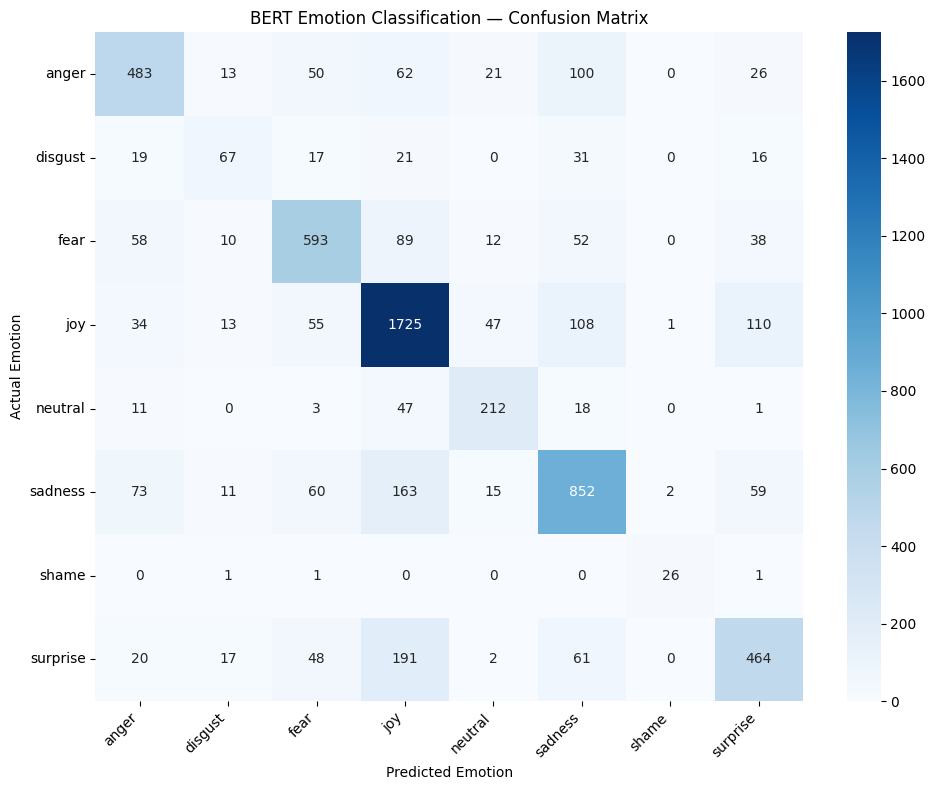

              precision    recall  f1-score   support

       anger       0.69      0.64      0.66       755
     disgust       0.51      0.39      0.44       171
        fear       0.72      0.70      0.71       852
         joy       0.75      0.82      0.79      2093
     neutral       0.69      0.73      0.71       292
     sadness       0.70      0.69      0.69      1235
       shame       0.90      0.90      0.90        29
    surprise       0.65      0.58      0.61       803

    accuracy                           0.71      6230
   macro avg       0.70      0.68      0.69      6230
weighted avg       0.71      0.71      0.71      6230



In [ ]:

cm = confusion_matrix(
    y_test_bert,
    y_pred_bert,
    labels=np.arange(num_labels)
)

plt.figure(figsize=(10, 8))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)

plt.title("BERT Emotion Classification — Confusion Matrix")
plt.xlabel("Predicted Emotion")
plt.ylabel("Actual Emotion")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

print(classification_report(
    y_test_bert,
    y_pred_bert,
    labels=np.arange(num_labels),
    target_names=label_encoder.classes_,
    zero_division=0
))


In [ ]:

# Build a test analysis table
error_df = test_df.reset_index(drop=True).copy()

error_df["true_id"] = y_test_bert
error_df["predicted_id"] = y_pred_bert

error_df["True Emotion"] = label_encoder.inverse_transform(
    error_df["true_id"].to_numpy()
)

error_df["Predicted Emotion"] = label_encoder.inverse_transform(
    error_df["predicted_id"].to_numpy()
)

error_df["Correct"] = (
    error_df["true_id"] == error_df["predicted_id"]
)

# 1. What is actual disgust being confused with?
disgust_missed = error_df[
    (error_df["True Emotion"] == "disgust") &
    (~error_df["Correct"])
]

print("Actual disgust examples missed:", len(disgust_missed))
print("\nPredictions for actual disgust examples:")

display(
    disgust_missed["Predicted Emotion"]
    .value_counts()
    .rename_axis("Predicted Emotion")
    .reset_index(name="Count")
)

# 2. What emotions are incorrectly predicted as disgust?
false_disgust = error_df[
    (error_df["Predicted Emotion"] == "disgust") &
    (error_df["True Emotion"] != "disgust")
]

print("\nOther emotions incorrectly predicted as disgust:", len(false_disgust))

display(
    false_disgust["True Emotion"]
    .value_counts()
    .rename_axis("Actual Emotion")
    .reset_index(name="Count")
)

# 3. Inspect real examples
print("\nExamples of missed disgust cases:")
display(
    disgust_missed[
        ["Text", "True Emotion", "Predicted Emotion"]
    ].head(20)
)


Actual disgust examples missed: 104

Predictions for actual disgust examples:


,Predicted Emotion,Count
0,sadness,31
1,joy,21
2,anger,19
3,fear,17
4,surprise,16



Other emotions incorrectly predicted as disgust: 65


,Actual Emotion,Count
0,surprise,17
1,anger,13
2,joy,13
3,sadness,11
4,fear,10
5,shame,1



Examples of missed disgust cases:


,Text,True Emotion,Predicted Emotion
191,&quot;oh i got so fucked up last night&quot; b...,disgust,sadness
265,i hate twitter spam.,disgust,anger
370,Literally discussing shit in class.,disgust,anger
505,"Forgot my water bottle in my car, so I spent $...",disgust,surprise
579,Some people actually say 'my bit' instead of '...,disgust,anger
672,drugs are bad i dont like when people brag abo...,disgust,anger
683,Horrible experience @toysrus Never going back....,disgust,fear
765,I know the usual feeling of being wolf whistle...,disgust,joy
866,"@ayushmannk ,,,shud have put kambli in some re...",disgust,sadness
934,maybe its a good Idea 2 recall our in &amp; ...,disgust,fear


,Emotion,Training Samples
3,joy,7534
5,sadness,4445
2,fear,3069
7,surprise,2891
0,anger,2718
4,neutral,1049
1,disgust,616
6,shame,103


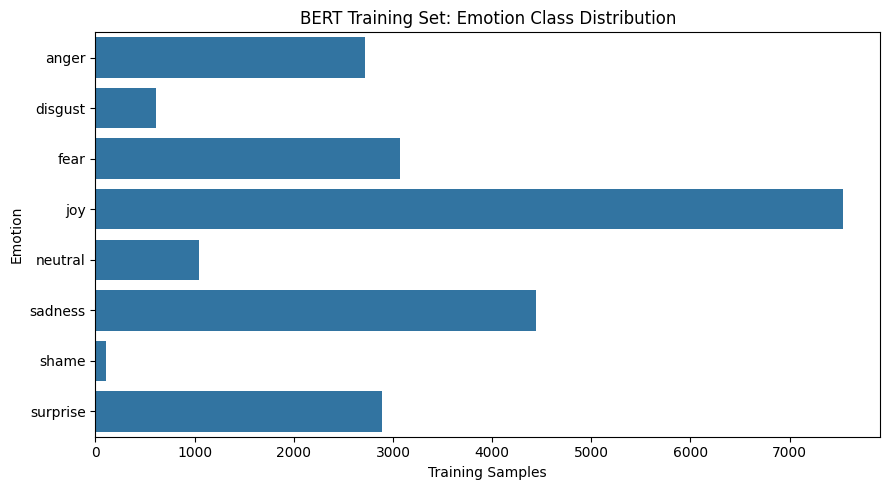

In [ ]:

# Training-set class distribution
class_counts = (
    train_df["Emotion"]
    .value_counts()
    .reindex(label_encoder.classes_, fill_value=0)
)

imbalance_df = pd.DataFrame({
    "Emotion": class_counts.index,
    "Training Samples": class_counts.values
})

display(
    imbalance_df.sort_values(
        "Training Samples", ascending=False
    )
)

plt.figure(figsize=(9, 5))
sns.barplot(
    data=imbalance_df,
    x="Training Samples",
    y="Emotion"
)
plt.title("BERT Training Set: Emotion Class Distribution")
plt.tight_layout()
plt.show()


In [ ]:

import torch
import numpy as np
from sklearn.utils.class_weight import compute_class_weight

# Use training labels only
classes = np.arange(num_labels)
train_labels = train_df["label"].to_numpy()

class_counts = np.bincount(
    train_labels, minlength=num_labels
)

# Moderate weighting: square root of inverse class frequency
class_weights = np.sqrt(
    len(train_labels) / (num_labels * class_counts)
)

# Normalize weights to have mean 1
class_weights = class_weights / class_weights.mean()

class_weights_tensor = torch.tensor(
    class_weights,
    dtype=torch.float32
)

weight_table = pd.DataFrame({
    "Emotion": label_encoder.classes_,
    "Training Samples": class_counts,
    "Class Weight": class_weights
})

display(weight_table.round(3))


,Emotion,Training Samples,Class Weight
0,anger,2718,0.609
1,disgust,616,1.279
2,fear,3069,0.573
3,joy,7534,0.366
4,neutral,1049,0.980
5,sadness,4445,0.476
6,shame,103,3.127
7,surprise,2891,0.590


In [ ]:

import torch
import torch.nn as nn
from transformers import Trainer

class WeightedTrainer(Trainer):
    def __init__(self, *args, class_weights=None, **kwargs):
        super().__init__(*args, **kwargs)
        self.class_weights = class_weights

    def compute_loss(
        self,
        model,
        inputs,
        return_outputs=False,
        num_items_in_batch=None
    ):
        labels = inputs.pop("labels")
        outputs = model(**inputs)

        weights = self.class_weights.to(
            outputs.logits.device
        )

        loss_function = nn.CrossEntropyLoss(
            weight=weights
        )

        loss = loss_function(
            outputs.logits.view(-1, model.config.num_labels),
            labels.view(-1)
        )

        return (loss, outputs) if return_outputs else loss


In [ ]:

from transformers import (
    AutoModelForSequenceClassification,
    TrainingArguments,
    DataCollatorWithPadding
)
import time

weighted_model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=num_labels,
    id2label=id2label,
    label2id=label2id
)

weighted_args = TrainingArguments(
    output_dir="./bert_emotion_weighted",
    eval_strategy="epoch",
    save_strategy="epoch",
    logging_strategy="epoch",
    learning_rate=2e-5,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=32,
    num_train_epochs=3,
    weight_decay=0.01,
    load_best_model_at_end=True,
    metric_for_best_model="macro_f1",
    greater_is_better=True,
    save_total_limit=2,
    fp16=torch.cuda.is_available(),
    report_to="none",
    seed=42,
    data_seed=42
)

weighted_trainer = WeightedTrainer(
    model=weighted_model,
    args=weighted_args,
    train_dataset=train_dataset,
    eval_dataset=val_dataset,
    processing_class=tokenizer,
    data_collator=data_collator,
    compute_metrics=compute_metrics,
    class_weights=class_weights_tensor
)

start_time = time.time()
weighted_trainer.train()
weighted_training_time = time.time() - start_time

print(
    "Weighted training time:",
    round(weighted_training_time / 60, 2),
    "minutes"
)


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: google-bert/bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,Accuracy,Macro Precision,Macro Recall,Macro F1
1,1.168367,0.874578,0.686998,0.680942,0.702116,0.683038
2,0.700856,0.844220,0.711477,0.691421,0.717898,0.701155
3,0.458440,0.886130,0.717095,0.697054,0.719286,0.705303


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[transformers] There were missing keys in the checkpoint model loaded: ['bert.embeddings.LayerNorm.weight', 'bert.embeddings.LayerNorm.bias', 'bert.encoder.layer.0.attention.output.LayerNorm.weight', 'bert.encoder.layer.0.attention.output.LayerNorm.bias', 'bert.encoder.layer.0.output.LayerNorm.weight', 'bert.encoder.layer.0.output.LayerNorm.bias', 'bert.encoder.layer.1.attention.output.LayerNorm.weight', 'bert.encoder.layer.1.attention.output.LayerNorm.bias', 'bert.encoder.layer.1.output.LayerNorm.weight', 'bert.encoder.layer.1.output.LayerNorm.bias', 'bert.encoder.layer.2.attention.output.LayerNorm.weight', 'bert.encoder.layer.2.attention.output.LayerNorm.bias', 'bert.encoder.layer.2.output.LayerNorm.weight', 'bert.encoder.layer.2.output.LayerNorm.bias', 'bert.encoder.layer.3.attention.output.LayerNorm.weight', 'bert.encoder.layer.3.attention.output.LayerNorm.bias', 'bert.encoder.layer.3.output.LayerNorm.weight', 'bert.encoder.layer.3.output.LayerNorm.bias', 'bert.encoder.layer.4.atte

Weighted training time: 6.75 minutes


In [ ]:

val_output = weighted_trainer.predict(val_dataset)

val_true = val_output.label_ids
val_pred = np.argmax(val_output.predictions, axis=-1)

print(classification_report(
    val_true,
    val_pred,
    labels=np.arange(num_labels),
    target_names=label_encoder.classes_,
    zero_division=0
))

val_metrics = compute_metrics(
    (val_output.predictions, val_true)
)

print("Validation metrics:", val_metrics)


              precision    recall  f1-score   support

       anger       0.68      0.69      0.68       302
     disgust       0.53      0.44      0.48        68
        fear       0.73      0.75      0.74       341
         joy       0.81      0.76      0.78       837
     neutral       0.57      0.78      0.66       117
     sadness       0.70      0.72      0.71       494
       shame       0.92      1.00      0.96        12
    surprise       0.64      0.61      0.63       321

    accuracy                           0.72      2492
   macro avg       0.70      0.72      0.71      2492
weighted avg       0.72      0.72      0.72      2492

Validation metrics: {'accuracy': 0.7170947030497592, 'macro_precision': 0.697054103468936, 'macro_recall': 0.7192857827253083, 'macro_f1': 0.7053029815946857}


In [ ]:

import numpy as np
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support
)

def evaluate_model_on_validation(trainer, model_name):
    output = trainer.predict(val_dataset)
    y_true = output.label_ids
    y_pred = np.argmax(output.predictions, axis=-1)

    precision, recall, f1, _ = precision_recall_fscore_support(
        y_true,
        y_pred,
        labels=np.arange(num_labels),
        zero_division=0
    )

    disgust_id = label2id["disgust"]

    return {
        "Model": model_name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Macro Precision": precision.mean(),
        "Macro Recall": recall.mean(),
        "Macro F1": f1.mean(),
        "Disgust Precision": precision[disgust_id],
        "Disgust Recall": recall[disgust_id],
        "Disgust F1": f1[disgust_id]
    }

same_validation_comparison = pd.DataFrame([
    evaluate_model_on_validation(trainer, "Original BERT"),
    evaluate_model_on_validation(weighted_trainer, "Weighted BERT")
])

display(
    same_validation_comparison.round(4)
)


,Model,Accuracy,Macro Precision,Macro Recall,Macro F1,Disgust Precision,Disgust Recall,Disgust F1
0,Original BERT,0.7299,0.7240,0.7133,0.7157,0.5870,0.3971,0.4737
1,Weighted BERT,0.7171,0.6971,0.7193,0.7053,0.5263,0.4412,0.4800


In [ ]:

from transformers import (
    AutoModelForSequenceClassification,
    TrainingArguments,
    Trainer
)
import time
import torch

# Start from the same pretrained BERT checkpoint
bert_lr1e5 = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=num_labels,
    id2label=id2label,
    label2id=label2id
)

lr1e5_args = TrainingArguments(
    output_dir="./bert_emotion_lr1e5",
    eval_strategy="epoch",
    save_strategy="epoch",
    logging_strategy="epoch",
    learning_rate=1e-5,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=32,
    num_train_epochs=3,
    weight_decay=0.01,
    load_best_model_at_end=True,
    metric_for_best_model="macro_f1",
    greater_is_better=True,
    save_total_limit=2,
    fp16=torch.cuda.is_available(),
    report_to="none",
    seed=42,
    data_seed=42
)

trainer_lr1e5 = Trainer(
    model=bert_lr1e5,
    args=lr1e5_args,
    train_dataset=train_dataset,
    eval_dataset=val_dataset,
    processing_class=tokenizer,
    data_collator=data_collator,
    compute_metrics=compute_metrics
)

start = time.time()
trainer_lr1e5.train()
lr1e5_training_time = time.time() - start

print(
    "Training time:",
    round(lr1e5_training_time / 60, 2),
    "minutes"
)


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: google-bert/bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,Accuracy,Macro Precision,Macro Recall,Macro F1
1,1.231101,0.940017,0.664526,0.478602,0.504430,0.489569
2,0.840173,0.862424,0.688604,0.678355,0.640699,0.647312
3,0.690016,0.854184,0.695425,0.691710,0.647831,0.660348


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[transformers] There were missing keys in the checkpoint model loaded: ['bert.embeddings.LayerNorm.weight', 'bert.embeddings.LayerNorm.bias', 'bert.encoder.layer.0.attention.output.LayerNorm.weight', 'bert.encoder.layer.0.attention.output.LayerNorm.bias', 'bert.encoder.layer.0.output.LayerNorm.weight', 'bert.encoder.layer.0.output.LayerNorm.bias', 'bert.encoder.layer.1.attention.output.LayerNorm.weight', 'bert.encoder.layer.1.attention.output.LayerNorm.bias', 'bert.encoder.layer.1.output.LayerNorm.weight', 'bert.encoder.layer.1.output.LayerNorm.bias', 'bert.encoder.layer.2.attention.output.LayerNorm.weight', 'bert.encoder.layer.2.attention.output.LayerNorm.bias', 'bert.encoder.layer.2.output.LayerNorm.weight', 'bert.encoder.layer.2.output.LayerNorm.bias', 'bert.encoder.layer.3.attention.output.LayerNorm.weight', 'bert.encoder.layer.3.attention.output.LayerNorm.bias', 'bert.encoder.layer.3.output.LayerNorm.weight', 'bert.encoder.layer.3.output.LayerNorm.bias', 'bert.encoder.layer.4.atte

Training time: 7.04 minutes


In [ ]:

learning_rate_comparison = pd.DataFrame([
    evaluate_model_on_validation(trainer, "Original BERT (2e-5)"),
    evaluate_model_on_validation(weighted_trainer, "Weighted BERT (2e-5)"),
    evaluate_model_on_validation(trainer_lr1e5, "Original loss (1e-5)")
])

display(
    learning_rate_comparison.round(4)
)


,Model,Accuracy,Macro Precision,Macro Recall,Macro F1,Disgust Precision,Disgust Recall,Disgust F1
0,Original BERT (2e-5),0.7299,0.7240,0.7133,0.7157,0.5870,0.3971,0.4737
1,Weighted BERT (2e-5),0.7171,0.6971,0.7193,0.7053,0.5263,0.4412,0.4800
2,Original loss (1e-5),0.6954,0.6917,0.6478,0.6603,0.4815,0.1912,0.2737


In [ ]:

import numpy as np
import torch
from transformers import AutoModel, AutoTokenizer
from torch.utils.data import DataLoader
from tqdm.auto import tqdm

# Load the pretrained BERT encoder
# This extracts features rather than using the emotion classifier head.
encoder = AutoModel.from_pretrained(MODEL_NAME)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)
encoder = encoder.to(device)
encoder.eval()

def extract_bert_embeddings(texts, batch_size=32):
    all_embeddings = []

    for start in tqdm(range(0, len(texts), batch_size)):
        batch_texts = texts[start:start + batch_size].tolist()

        encoded = tokenizer(
            batch_texts,
            padding=True,
            truncation=True,
            max_length=128,
            return_tensors="pt"
        )

        encoded = {
            key: value.to(device)
            for key, value in encoded.items()
        }

        with torch.no_grad():
            outputs = encoder(**encoded)

            # Final hidden state of the [CLS] token
            cls_embeddings = outputs.last_hidden_state[:, 0, :]

        all_embeddings.append(
            cls_embeddings.cpu().numpy()
        )

    return np.vstack(all_embeddings)

X_train_bert = extract_bert_embeddings(
    train_df["Text"].astype(str)
)
X_val_bert = extract_bert_embeddings(
    val_df["Text"].astype(str)
)
X_test_bert = extract_bert_embeddings(
    test_df["Text"].astype(str)
)

print("Train:", X_train_bert.shape)
print("Validation:", X_val_bert.shape)
print("Test:", X_test_bert.shape)


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: google-bert/bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


  0%|          | 0/701 [00:00<?, ?it/s]

  0%|          | 0/78 [00:00<?, ?it/s]

  0%|          | 0/195 [00:00<?, ?it/s]

Train: (22425, 768)
Validation: (2492, 768)
Test: (6230, 768)


In [ ]:

from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
import pandas as pd
import time

# Scale using training data only
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train_bert)
X_val_scaled = scaler.transform(X_val_bert)

lr_results = []
lr_models = {}

for C in [0.01, 0.1, 1.0, 10.0]:
    print(f"Training Logistic Regression, C={C}")

    lr = LogisticRegression(
        C=C,
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    )

    start = time.time()
    lr.fit(X_train_scaled, y_train)
    val_pred = lr.predict(X_val_scaled)
    elapsed = time.time() - start

    lr_models[C] = lr

    lr_results.append({
        "C": C,
        "Accuracy": accuracy_score(y_val, val_pred),
        "Macro Precision": precision_score(
            y_val, val_pred, average="macro", zero_division=0
        ),
        "Macro Recall": recall_score(
            y_val, val_pred, average="macro", zero_division=0
        ),
        "Macro F1": f1_score(
            y_val, val_pred, average="macro", zero_division=0
        ),
        "Time (seconds)": round(elapsed, 2)
    })

lr_results_df = pd.DataFrame(lr_results)

display(
    lr_results_df.sort_values(
        "Macro F1", ascending=False
    ).round(4)
)



Training Logistic Regression, C=0.01
Training Logistic Regression, C=0.1
Training Logistic Regression, C=1.0
Training Logistic Regression, C=10.0


,C,Accuracy,Macro Precision,Macro Recall,Macro F1,Time (seconds)
0,0.01,0.5393,0.4718,0.5899,0.4972,27.57
1,0.10,0.5301,0.4710,0.5623,0.4926,40.15
2,1.00,0.5273,0.4718,0.5473,0.4887,51.25
3,10.00,0.5281,0.4710,0.5377,0.4842,50.50


In [ ]:

display(
    lr_results_df[
        [
            "C",
            "Accuracy",
            "Macro Precision",
            "Macro Recall",
            "Macro F1",
            "Time (seconds)"
        ]
    ].sort_values("Macro F1", ascending=False).round(4)
)


,C,Accuracy,Macro Precision,Macro Recall,Macro F1,Time (seconds)
0,0.01,0.5393,0.4718,0.5899,0.4972,27.57
1,0.10,0.5301,0.4710,0.5623,0.4926,40.15
2,1.00,0.5273,0.4718,0.5473,0.4887,51.25
3,10.00,0.5281,0.4710,0.5377,0.4842,50.50


In [ ]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)
import pandas as pd

best_C = 0.01
best_lr = lr_models[best_C]

# Transform test embeddings using the scaler fitted on training data
X_test_scaled = scaler.transform(X_test_bert)

test_pred_lr = best_lr.predict(X_test_scaled)

lr_test_results = pd.DataFrame([{
    "Model": "BERT embeddings + Logistic Regression",
    "C": best_C,
    "Accuracy": accuracy_score(y_test, test_pred_lr),
    "Macro Precision": precision_score(
        y_test, test_pred_lr,
        average="macro", zero_division=0
    ),
    "Macro Recall": recall_score(
        y_test, test_pred_lr,
        average="macro", zero_division=0
    ),
    "Macro F1": f1_score(
        y_test, test_pred_lr,
        average="macro", zero_division=0
    )
}])

display(lr_test_results.round(4))

print(classification_report(
    y_test,
    test_pred_lr,
    labels=np.arange(num_labels),
    target_names=label_encoder.classes_,
    zero_division=0
))


,Model,C,Accuracy,Macro Precision,Macro Recall,Macro F1
0,BERT embeddings + Logistic Regression,0.01,0.551,0.4748,0.5789,0.5


              precision    recall  f1-score   support

       anger       0.50      0.50      0.50       755
     disgust       0.17      0.52      0.26       171
        fear       0.54      0.54      0.54       852
         joy       0.76      0.56      0.65      2093
     neutral       0.51      0.85      0.64       292
     sadness       0.58      0.52      0.55      1235
       shame       0.27      0.62      0.38        29
    surprise       0.46      0.52      0.49       803

    accuracy                           0.55      6230
   macro avg       0.47      0.58      0.50      6230
weighted avg       0.59      0.55      0.56      6230



In [ ]:

import time
import pandas as pd

from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

svm_results = []
svm_models = {}

for C in [0.01, 0.1, 1.0, 10.0]:
    print(f"Training Linear SVM, C={C}")

    svm = LinearSVC(
        C=C,
        class_weight="balanced",
        max_iter=5000,
        random_state=42
    )

    start = time.time()
    svm.fit(X_train_scaled, y_train)
    val_pred = svm.predict(X_val_scaled)
    elapsed = time.time() - start

    svm_models[C] = svm

    svm_results.append({
        "C": C,
        "Accuracy": accuracy_score(y_val, val_pred),
        "Macro Precision": precision_score(
            y_val, val_pred,
            average="macro", zero_division=0
        ),
        "Macro Recall": recall_score(
            y_val, val_pred,
            average="macro", zero_division=0
        ),
        "Macro F1": f1_score(
            y_val, val_pred,
            average="macro", zero_division=0
        ),
        "Time (seconds)": round(elapsed, 2)
    })

svm_results_df = pd.DataFrame(svm_results)

display(
    svm_results_df.sort_values(
        "Macro F1", ascending=False
    ).round(4)
)


Training Linear SVM, C=0.01
Training Linear SVM, C=0.1
Training Linear SVM, C=1.0


/usr/local/lib/python3.13/dist-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


Training Linear SVM, C=10.0


/usr/local/lib/python3.13/dist-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


,C,Accuracy,Macro Precision,Macro Recall,Macro F1,Time (seconds)
0,0.01,0.5598,0.4958,0.5728,0.5156,72.43
3,10.00,0.5582,0.4938,0.5477,0.5050,272.72
1,0.10,0.5570,0.4885,0.5478,0.5020,107.10
2,1.00,0.5578,0.4833,0.5373,0.4946,282.50


In [ ]:

import time
import pandas as pd

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

rf_models = {
    "RF Default": RandomForestClassifier(
        n_estimators=100,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ),

    "RF 200 Trees": RandomForestClassifier(
        n_estimators=200,
        max_features="sqrt",
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ),

    "RF Deep Trees": RandomForestClassifier(
        n_estimators=100,
        max_depth=30,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ),

    "RF Regularized": RandomForestClassifier(
        n_estimators=200,
        max_depth=20,
        min_samples_leaf=2,
        max_features="sqrt",
        class_weight="balanced_subsample",
        random_state=42,
        n_jobs=-1
    )
}

rf_results = []
rf_trained_models = {}
rf_val_predictions = {}

for name, rf in rf_models.items():
    print(f"Training {name}...")

    start = time.time()

    rf.fit(X_train_bert, y_train)
    val_pred = rf.predict(X_val_bert)

    elapsed = time.time() - start

    rf_trained_models[name] = rf
    rf_val_predictions[name] = val_pred

    rf_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_val, val_pred),
        "Macro Precision": precision_score(
            y_val, val_pred,
            average="macro", zero_division=0
        ),
        "Macro Recall": recall_score(
            y_val, val_pred,
            average="macro", zero_division=0
        ),
        "Macro F1": f1_score(
            y_val, val_pred,
            average="macro", zero_division=0
        ),
        "Time (seconds)": round(elapsed, 2)
    })

rf_results_df = pd.DataFrame(rf_results)

display(
    rf_results_df.sort_values(
        "Macro F1", ascending=False
    ).round(4)
)


Training RF Default...
Training RF 200 Trees...
Training RF Deep Trees...
Training RF Regularized...


,Model,Accuracy,Macro Precision,Macro Recall,Macro F1,Time (seconds)
3,RF Regularized,0.5281,0.5549,0.3535,0.3725,140.23
1,RF 200 Trees,0.5052,0.4802,0.3119,0.3368,150.58
2,RF Deep Trees,0.4964,0.4468,0.3102,0.3316,75.50
0,RF Default,0.4988,0.4478,0.3083,0.3299,84.31


In [ ]:

import time
import pandas as pd

from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

dt_models = {
    "DT Default": DecisionTreeClassifier(
        class_weight="balanced",
        random_state=42
    ),

    "DT Entropy": DecisionTreeClassifier(
        criterion="entropy",
        class_weight="balanced",
        random_state=42
    ),

    "DT Limited Depth": DecisionTreeClassifier(
        max_depth=20,
        class_weight="balanced",
        random_state=42
    ),

    "DT Regularized": DecisionTreeClassifier(
        max_depth=20,
        min_samples_split=10,
        min_samples_leaf=5,
        class_weight="balanced",
        random_state=42
    )
}

dt_results = []
dt_trained_models = {}
dt_val_predictions = {}

for name, dt in dt_models.items():
    print(f"Training {name}...")

    start = time.time()
    dt.fit(X_train_bert, y_train)
    val_pred = dt.predict(X_val_bert)
    elapsed = time.time() - start

    dt_trained_models[name] = dt
    dt_val_predictions[name] = val_pred

    dt_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_val, val_pred),
        "Macro Precision": precision_score(
            y_val, val_pred,
            average="macro", zero_division=0
        ),
        "Macro Recall": recall_score(
            y_val, val_pred,
            average="macro", zero_division=0
        ),
        "Macro F1": f1_score(
            y_val, val_pred,
            average="macro", zero_division=0
        ),
        "Time (seconds)": round(elapsed, 2)
    })

dt_results_df = pd.DataFrame(dt_results)

display(
    dt_results_df.sort_values(
        "Macro F1", ascending=False
    ).round(4)
)


Training DT Default...
Training DT Entropy...
Training DT Limited Depth...
Training DT Regularized...


,Model,Accuracy,Macro Precision,Macro Recall,Macro F1,Time (seconds)
2,DT Limited Depth,0.3291,0.2684,0.2808,0.2736,48.75
3,DT Regularized,0.3178,0.2621,0.2949,0.2712,45.66
0,DT Default,0.3359,0.2751,0.2680,0.2711,56.05
1,DT Entropy,0.3375,0.2739,0.2667,0.2684,73.97


In [ ]:

from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

best_svm = svm_models[0.01]

X_test_scaled = scaler.transform(X_test_bert)
test_pred_svm = best_svm.predict(X_test_scaled)

svm_test_results = pd.DataFrame([{
    "Model": "Frozen BERT Embeddings + Linear SVM",
    "C": 0.01,
    "Accuracy": accuracy_score(y_test, test_pred_svm),
    "Macro Precision": precision_score(
        y_test, test_pred_svm,
        average="macro", zero_division=0
    ),
    "Macro Recall": recall_score(
        y_test, test_pred_svm,
        average="macro", zero_division=0
    ),
    "Macro F1": f1_score(
        y_test, test_pred_svm,
        average="macro", zero_division=0
    )
}])

display(svm_test_results.round(4))

print(classification_report(
    y_test,
    test_pred_svm,
    labels=np.arange(num_labels),
    target_names=label_encoder.classes_,
    zero_division=0
))


,Model,C,Accuracy,Macro Precision,Macro Recall,Macro F1
0,Frozen BERT Embeddings + Linear SVM,0.01,0.5689,0.48,0.5485,0.4986


              precision    recall  f1-score   support

       anger       0.51      0.51      0.51       755
     disgust       0.19      0.50      0.27       171
        fear       0.55      0.53      0.54       852
         joy       0.72      0.64      0.68      2093
     neutral       0.51      0.79      0.62       292
     sadness       0.59      0.54      0.56      1235
       shame       0.25      0.41      0.31        29
    surprise       0.51      0.46      0.49       803

    accuracy                           0.57      6230
   macro avg       0.48      0.55      0.50      6230
weighted avg       0.59      0.57      0.58      6230

